In [22]:
# 7.1 Environment Setup and Project Paths


from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from torchvision import models, transforms


# 1. Project directories


PROJECT_ROOT = "/content/drive/MyDrive/Projectwork/Betel_Leaf_Final"

STAGE4_ROOT = os.path.join(
    PROJECT_ROOT, "Stage4_Segmentation"
)

STAGE5_ROOT = os.path.join(
    PROJECT_ROOT, "Stage5_Hybrid_Representation"
)

STAGE6_ROOT = os.path.join(
    PROJECT_ROOT, "Stage6_Classifier_Finalization"
)

STAGE7_ROOT = os.path.join(
    PROJECT_ROOT, "Stage7_Integrated_Diagnostic_Pipeline"
)

os.makedirs(STAGE7_ROOT, exist_ok=True)


# 2. Model checkpoints


CLASSIFIER_CHECKPOINT = os.path.join(
    PROJECT_ROOT,
    "Stage2A_Results",
    "efficientnet_b0_best.pth"
)

SEGMENTATION_CHECKPOINT = os.path.join(
    STAGE4_ROOT,
    "Experiment_4B_Joint_BCEDice",
    "Checkpoints",
    "efficientnet_b0_unet_best.pth"
)


# 3. Geometric feature module


FEATURE_SCRIPT_DIR = os.path.join(
    STAGE5_ROOT,
    "Stage5_1_Geometric_Features",
    "Scripts"
)

FEATURE_MODULE_PATH = os.path.join(
    FEATURE_SCRIPT_DIR,
    "stage5_geometric_features.py"
)


# 4. Results directory


STAGE7_RESULTS = os.path.join(
    STAGE7_ROOT, "Results"
)

os.makedirs(STAGE7_RESULTS, exist_ok=True)


# 5. Device


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


print("STAGE 7 ENVIRONMENT INITIALIZED")


print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("\nFILE VERIFICATION")
print("Classifier checkpoint:",
      os.path.exists(CLASSIFIER_CHECKPOINT))

print("Segmentation checkpoint:",
      os.path.exists(SEGMENTATION_CHECKPOINT))

print("Geometric feature module:",
      os.path.exists(FEATURE_MODULE_PATH))

print("\nStage 7 directory:", STAGE7_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STAGE 7 ENVIRONMENT INITIALIZED
Device: cpu

FILE VERIFICATION
Classifier checkpoint: True
Segmentation checkpoint: True
Geometric feature module: True

Stage 7 directory: /content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage7_Integrated_Diagnostic_Pipeline


In [23]:
# STAGE 7.2 — LOAD AND VERIFY CLASSIFICATION MODEL

import torch
import torch.nn as nn
from torchvision import models

# Load checkpoint
classifier_checkpoint = torch.load(
    CLASSIFIER_CHECKPOINT,
    map_location=device,
    weights_only=False
)

# Reconstruct EfficientNet-B0 architecture
classifier_model = models.efficientnet_b0(weights=None)
classifier_model.classifier[1] = nn.Linear(1280, 3)

# Load trained weights
classifier_model.load_state_dict(
    classifier_checkpoint["model_state_dict"],
    strict=True
)

classifier_model = classifier_model.to(device)
classifier_model.eval()

# Verify metadata
class_names = classifier_checkpoint["classes"]
class_to_idx = classifier_checkpoint["class_to_idx"]

# Count parameters
classifier_params = sum(
    p.numel() for p in classifier_model.parameters()
)

print("CLASSIFIER LOADED SUCCESSFULLY")
print("Architecture: EfficientNet-B0")
print("Classes:", class_names)
print("Class mapping:", class_to_idx)
print("Best epoch:", classifier_checkpoint["best_epoch"])
print(
    "Best validation Macro-F1:",
    round(classifier_checkpoint["best_val_macro_f1"], 4)
)
print("Parameters:", f"{classifier_params:,}")
print("Device:", next(classifier_model.parameters()).device)
print("Evaluation mode:", not classifier_model.training)

CLASSIFIER LOADED SUCCESSFULLY
Architecture: EfficientNet-B0
Classes: ['bacterial', 'fungal', 'healthy']
Class mapping: {'bacterial': 0, 'fungal': 1, 'healthy': 2}
Best epoch: 13
Best validation Macro-F1: 0.982
Parameters: 4,011,391
Device: cpu
Evaluation mode: True


In [24]:
# STAGE 7.3 — RECONSTRUCT AND LOAD EXACT SEGMENTATION MODEL

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models

# 1. Original Stage 4 convolution block


class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# 2. Exact EfficientNet-B0 U-Net from Stage 4

class EfficientNetB0_UNet(nn.Module):

    def __init__(self, pretrained=True):
        super().__init__()

        weights = (
            models.EfficientNet_B0_Weights.DEFAULT
            if pretrained else None
        )

        backbone = models.efficientnet_b0(weights=weights)

        self.encoder = backbone.features

        self.center = ConvBlock(1280, 256)

        self.decoder4 = ConvBlock(256 + 112, 256)
        self.decoder3 = ConvBlock(256 + 40, 128)
        self.decoder2 = ConvBlock(128 + 24, 64)
        self.decoder1 = ConvBlock(64 + 32, 64)

        self.final_conv = nn.Sequential(
            ConvBlock(64, 32),
            nn.Conv2d(32, 2, kernel_size=1)
        )

    def forward(self, x):

        input_size = x.shape[2:]

        e1 = self.encoder[0](x)

        x = self.encoder[1](e1)
        e2 = self.encoder[2](x)

        e3 = self.encoder[3](e2)

        x = self.encoder[4](e3)
        e4 = self.encoder[5](x)

        x = self.encoder[6](e4)
        x = self.encoder[7](x)
        e5 = self.encoder[8](x)

        center = self.center(e5)

        d4 = F.interpolate(
            center,
            size=e4.shape[2:],
            mode="bilinear",
            align_corners=False
        )
        d4 = self.decoder4(torch.cat([d4, e4], dim=1))

        d3 = F.interpolate(
            d4,
            size=e3.shape[2:],
            mode="bilinear",
            align_corners=False
        )
        d3 = self.decoder3(torch.cat([d3, e3], dim=1))

        d2 = F.interpolate(
            d3,
            size=e2.shape[2:],
            mode="bilinear",
            align_corners=False
        )
        d2 = self.decoder2(torch.cat([d2, e2], dim=1))

        d1 = F.interpolate(
            d2,
            size=e1.shape[2:],
            mode="bilinear",
            align_corners=False
        )
        d1 = self.decoder1(torch.cat([d1, e1], dim=1))

        output = F.interpolate(
            d1,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )

        return self.final_conv(output)


# 3. Load trained checkpoint

segmentation_checkpoint = torch.load(
    SEGMENTATION_CHECKPOINT,
    map_location=device,
    weights_only=False
)

segmentation_model = EfficientNetB0_UNet(
    pretrained=False
).to(device)

segmentation_model.load_state_dict(
    segmentation_checkpoint["model_state_dict"],
    strict=True
)

segmentation_model.eval()

# 4. Verification

segmentation_params = sum(
    p.numel() for p in segmentation_model.parameters()
)

print("SEGMENTATION MODEL LOADED SUCCESSFULLY")
print("Architecture: EfficientNet-B0 U-Net")
print("Checkpoint epoch:", segmentation_checkpoint["epoch"])
print("Best validation loss:",
      segmentation_checkpoint["best_val_loss"])
print("Output channels: 2 (Leaf, Lesion)")
print("Parameters:", f"{segmentation_params:,}")
print("Device:", next(segmentation_model.parameters()).device)
print("Evaluation mode:", not segmentation_model.training)

SEGMENTATION MODEL LOADED SUCCESSFULLY
Architecture: EfficientNet-B0 U-Net
Checkpoint epoch: 38
Best validation loss: 0.12464878163127988
Output channels: 2 (Leaf, Lesion)
Parameters: 9,720,126
Device: cpu
Evaluation mode: True


In [25]:
# Stage 7.4: Verify segmentation model forward pass

segmentation_model.eval()

with torch.no_grad():
    dummy_input = torch.randn(1, 3, 512, 512).to(device)
    dummy_output = segmentation_model(dummy_input)

print("SEGMENTATION FORWARD-PASS VERIFICATION")
print("Input shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(dummy_output.shape))
print("Expected output shape:", (1, 2, 512, 512))
print("Output contains finite values:", torch.isfinite(dummy_output).all().item())

dummy_probabilities = torch.sigmoid(dummy_output)

print("Probability minimum:", dummy_probabilities.min().item())
print("Probability maximum:", dummy_probabilities.max().item())

print("\nGPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

SEGMENTATION FORWARD-PASS VERIFICATION
Input shape: (1, 3, 512, 512)
Output shape: (1, 2, 512, 512)
Expected output shape: (1, 2, 512, 512)
Output contains finite values: True
Probability minimum: 6.398716504918411e-05
Probability maximum: 0.808850884437561

GPU available: False


In [26]:
# STAGE 7.5 — Verify models nad geometric feature models

import os
import importlib.util
import torch

# 1. Locate the original Stage 5 feature module
FEATURE_MODULE_PATH = os.path.join(
    PROJECT_ROOT,
    "Stage5_Hybrid_Representation",
    "Stage5_1_Geometric_Features",
    "Scripts",
    "stage5_geometric_features.py"
)

assert os.path.exists(FEATURE_MODULE_PATH), (
    f"Feature module not found: {FEATURE_MODULE_PATH}"
)

# 2. Import the original module without modifying it
spec = importlib.util.spec_from_file_location(
    "stage5_geometric_features",
    FEATURE_MODULE_PATH
)

geometric_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(geometric_module)

# 3. Verify the required feature-extraction functions
required_functions = [
    "extract_geometric_features",
    "extract_features_from_manifest"
]

for function_name in required_functions:
    assert callable(
        getattr(geometric_module, function_name, None)
    ), f"Missing function: {function_name}"

# 4. Verify the classifier
assert "classifier_model" in globals(), (
    "Classifier model is not loaded."
)

assert isinstance(classifier_model, torch.nn.Module)
assert not classifier_model.training

# 5. Verify the segmentation model
segmentation_model_obj = globals().get(
    "segmentation_model",
    globals().get("model", None)
)

assert segmentation_model_obj is not None, (
    "Segmentation model variable not found. "
    "Check the variable name used in Stage 7.3."
)

assert isinstance(segmentation_model_obj, torch.nn.Module)
assert not segmentation_model_obj.training

# 6. Verify the model checkpoints
assert os.path.exists(CLASSIFIER_CHECKPOINT)
assert os.path.exists(SEGMENTATION_CHECKPOINT)

# 7. Display verification results

print("STAGE 7.5 — COMPONENT VERIFICATION")


print("\nCLASSIFICATION MODEL")
print("Architecture: EfficientNet-B0")
print("Loaded:", True)
print("Evaluation mode:", not classifier_model.training)
print("Device:", next(classifier_model.parameters()).device)

print("\nSEGMENTATION MODEL")
print("Architecture: EfficientNet-B0 U-Net")
print("Loaded:", True)
print("Evaluation mode:", not segmentation_model_obj.training)
print("Device:", next(segmentation_model_obj.parameters()).device)

print("\nGEOMETRIC FEATURE MODULE")
print("Module:", FEATURE_MODULE_PATH)
print("Loaded:", True)

for function_name in required_functions:
    print(f"{function_name}: Available")

print("\nCHECKPOINT FILES")
print("Classifier checkpoint:", os.path.exists(CLASSIFIER_CHECKPOINT))
print("Segmentation checkpoint:", os.path.exists(SEGMENTATION_CHECKPOINT))

print("ALL THREE COMPONENTS VERIFIED SUCCESSFULLY.")


STAGE 7.5 — COMPONENT VERIFICATION

CLASSIFICATION MODEL
Architecture: EfficientNet-B0
Loaded: True
Evaluation mode: True
Device: cpu

SEGMENTATION MODEL
Architecture: EfficientNet-B0 U-Net
Loaded: True
Evaluation mode: True
Device: cpu

GEOMETRIC FEATURE MODULE
Module: /content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage5_Hybrid_Representation/Stage5_1_Geometric_Features/Scripts/stage5_geometric_features.py
Loaded: True
extract_geometric_features: Available
extract_features_from_manifest: Available

CHECKPOINT FILES
Classifier checkpoint: True
Segmentation checkpoint: True
ALL THREE COMPONENTS VERIFIED SUCCESSFULLY.


In [27]:
# STAGE 7.6 — SELECT ONE HELD-OUT TEST IMAGE

import os
import pandas as pd
from PIL import Image, ImageOps

STAGE5_ROOT = os.path.join(
    PROJECT_ROOT,
    "Stage5_Hybrid_Representation"
)

MANIFEST_PATH = os.path.join(
    STAGE5_ROOT,
    "Stage5_0_Project_Setup",
    "stage5_verified_manifest.csv"
)

# Load the verified Stage 5 manifest
stage7_manifest = pd.read_csv(MANIFEST_PATH)

# Select one test image
test_samples = (
    stage7_manifest[
        stage7_manifest["split"] == "test"
    ]
    .sort_values("filename")
    .reset_index(drop=True)
)

assert len(test_samples) > 0, "No test images found."

sample = test_samples.iloc[0]

IMAGE_PATH = sample["image_path_resolved"]
IMAGE_FILENAME = sample["filename"]
TRUE_CLASS = sample["class"]

assert os.path.exists(IMAGE_PATH), (
    f"Image not found: {IMAGE_PATH}"
)

# Verify image dimensions after EXIF correction
with Image.open(IMAGE_PATH) as img:
    original_image = ImageOps.exif_transpose(img).convert("RGB")
    ORIGINAL_WIDTH, ORIGINAL_HEIGHT = original_image.size


print("STAGE 7.6 — TEST IMAGE SELECTION")


print("Total test images:", len(test_samples))
print("Selected filename:", IMAGE_FILENAME)
print("Ground-truth class:", TRUE_CLASS)
print("Image path:", IMAGE_PATH)
print("Original dimensions:", ORIGINAL_WIDTH, "x", ORIGINAL_HEIGHT)
print("Image mode:", original_image.mode)

print("\nTest split class distribution:")
print(test_samples["class"].value_counts().to_dict())

print("\nImage selection verified successfully.")


STAGE 7.6 — TEST IMAGE SELECTION
Total test images: 108
Selected filename: Bacterial_Leaf_Spot_Disease(105).jpg
Ground-truth class: bacterial
Image path: /content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Betel Leaf/bacterial/Bacterial_Leaf_Spot_Disease(105).jpg
Original dimensions: 3000 x 3000
Image mode: RGB

Test split class distribution:
{'bacterial': 37, 'healthy': 37, 'fungal': 34}

Image selection verified successfully.


In [28]:
# STAGE 7.9 — REUSABLE INTEGRATED DIAGNOSIS FUNCTION


import os
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from torchvision import transforms


# 1. OUTPUT DIRECTORY


INTEGRATED_OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "Stage7_Integrated_Diagnostic_Pipeline",
    "Results",
    "Integrated_Inference"
)

os.makedirs(INTEGRATED_OUTPUT_DIR, exist_ok=True)


# 2. REUSABLE PREPROCESSING AND RESTORATION HELPERS


def stage7_resize_and_pad(image, target_size=512):

    width, height = image.size

    scale = min(
        target_size / width,
        target_size / height
    )

    new_width = max(1, round(width * scale))
    new_height = max(1, round(height * scale))

    resized = image.resize(
        (new_width, new_height),
        resample=Image.Resampling.BILINEAR
    )

    canvas = Image.new(
        "RGB",
        (target_size, target_size),
        color=(0, 0, 0)
    )

    left = (target_size - new_width) // 2
    top = (target_size - new_height) // 2

    canvas.paste(resized, (left, top))

    return canvas, new_width, new_height, left, top


def stage7_restore_mask(
    mask,
    original_width,
    original_height,
    new_width,
    new_height,
    left,
    top
):

    mask_image = Image.fromarray(
        mask.astype(np.uint8) * 255
    )

    mask_image = mask_image.crop((
        left,
        top,
        left + new_width,
        top + new_height
    ))

    mask_image = mask_image.resize(
        (original_width, original_height),
        resample=Image.Resampling.NEAREST
    )

    return np.array(mask_image) > 0



# 3. REUSABLE DIAGNOSTIC FUNCTION


def run_integrated_diagnosis(image_path, save_outputs=True):

    if not os.path.exists(image_path):
        raise FileNotFoundError(image_path)

    # Determine devices from the loaded models
    classifier_device = next(
        classifier_model.parameters()
    ).device

    segmentation_device = next(
        segmentation_model_obj.parameters()
    ).device

    # Load and correct original image orientation
    with Image.open(image_path) as img:
        classifier_image = img.convert("RGB")
        segmentation_original_image = (
            ImageOps.exif_transpose(img).convert("RGB")
        )

    original_width, original_height = segmentation_original_image.size

    filename = os.path.basename(image_path)
    basename = os.path.splitext(filename)[0]


    # CLASSIFICATION
    # Exact Stage 2A evaluation preprocessing


    classification_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    classification_tensor = (
        classification_transform(classifier_image)
        .unsqueeze(0)
        .to(classifier_device)
    )


    # SEGMENTATION
    # Exact Stage 5 inference preprocessing


    segmentation_image, new_width, new_height, left, top = (
        stage7_resize_and_pad(segmentation_original_image, 512)
    )

    segmentation_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    segmentation_tensor = (
        segmentation_transform(segmentation_image)
        .unsqueeze(0)
        .to(segmentation_device)
    )


    # MODEL INFERENCE


    with torch.inference_mode():

        class_logits = classifier_model(
            classification_tensor
        )

        class_probabilities = torch.softmax(
            class_logits, dim=1
        )[0].cpu().numpy()

        predicted_index = int(
            np.argmax(class_probabilities)
        )

        predicted_class = class_names[predicted_index]

        segmentation_logits = segmentation_model_obj(
            segmentation_tensor
        )

        segmentation_probabilities = torch.sigmoid(
            segmentation_logits
        )

        leaf_mask_512 = (
            segmentation_probabilities[0, 0] >= 0.5
        ).cpu().numpy()

        lesion_mask_512 = (
            segmentation_probabilities[0, 1] >= 0.5
        ).cpu().numpy()


    # RESTORE MASKS TO ORIGINAL DIMENSIONS


    leaf_mask = stage7_restore_mask(
        leaf_mask_512,
        original_width,
        original_height,
        new_width,
        new_height,
        left,
        top
    )

    lesion_mask = stage7_restore_mask(
        lesion_mask_512,
        original_width,
        original_height,
        new_width,
        new_height,
        left,
        top
    )


    # SAVE MASKS


    leaf_mask_path = None
    lesion_mask_path = None

    if save_outputs:

        image_output_dir = os.path.join(
            INTEGRATED_OUTPUT_DIR,
            basename
        )

        leaf_dir = os.path.join(
            image_output_dir, "leaf_masks"
        )

        lesion_dir = os.path.join(
            image_output_dir, "lesion_masks"
        )

        os.makedirs(leaf_dir, exist_ok=True)
        os.makedirs(lesion_dir, exist_ok=True)

        leaf_mask_path = os.path.join(
            leaf_dir, basename + "_leaf.png"
        )

        lesion_mask_path = os.path.join(
            lesion_dir, basename + "_lesion.png"
        )

        Image.fromarray(
            leaf_mask.astype(np.uint8) * 255
        ).save(leaf_mask_path)

        Image.fromarray(
            lesion_mask.astype(np.uint8) * 255
        ).save(lesion_mask_path)

    else:
        # Temporary masks are still needed for feature extraction.
        # Use in-memory files only when saving is disabled.
        import tempfile

        temp_dir = tempfile.mkdtemp(prefix="stage7_")

        leaf_mask_path = os.path.join(
            temp_dir, basename + "_leaf.png"
        )

        lesion_mask_path = os.path.join(
            temp_dir, basename + "_lesion.png"
        )

        Image.fromarray(
            leaf_mask.astype(np.uint8) * 255
        ).save(leaf_mask_path)

        Image.fromarray(
            lesion_mask.astype(np.uint8) * 255
        ).save(lesion_mask_path)


    # GEOMETRIC FEATURE EXTRACTION
    # Original Stage 5 module and formulas


    feature_input = pd.Series({
        "filename": filename,
        "class": predicted_class,
        "split": "inference",
        "leaf_mask_path": leaf_mask_path,
        "lesion_mask_path": lesion_mask_path
    })

    geometric_features = (
        geometric_module.extract_geometric_features(
            feature_input
        )
    )


    # STRUCTURED DIAGNOSTIC RESULT


    result = {
        "filename": filename,
        "image_path": image_path,
        "original_width": original_width,
        "original_height": original_height,
        "predicted_class": predicted_class,
        "class_confidence": float(
            class_probabilities[predicted_index]
        ),
        "class_probabilities": {
            class_names[i]: float(class_probabilities[i])
            for i in range(len(class_names))
        },
        "leaf_mask": leaf_mask,
        "lesion_mask": lesion_mask,
        "leaf_mask_path": leaf_mask_path,
        "lesion_mask_path": lesion_mask_path,
        "geometric_features": geometric_features
    }

    return result


print("Reusable integrated diagnosis function defined.")
print("Function name: run_integrated_diagnosis")
print("Classification preprocessing: verified")
print("Segmentation preprocessing: verified")
print("Segmentation threshold: 0.5")
print("Geometric extraction: original Stage 5 module")


Reusable integrated diagnosis function defined.
Function name: run_integrated_diagnosis
Classification preprocessing: verified
Segmentation preprocessing: verified
Segmentation threshold: 0.5
Geometric extraction: original Stage 5 module


In [29]:

# STAGE 7.9 — SINGLE IMAGE INTEGRATED VERIFICATION

print("Running integrated diagnosis on one test image...")

verification_result = run_integrated_diagnosis(
    IMAGE_PATH,
    save_outputs=True
)

print("\nINTEGRATED CLASSIFICATION")
print("Filename:", verification_result["filename"])
print("Actual class:", TRUE_CLASS)
print("Predicted class:", verification_result["predicted_class"])
print("Confidence:", round(verification_result["class_confidence"], 6))

print("\nCLASS PROBABILITIES")
for class_name, probability in verification_result["class_probabilities"].items():
    print(f"{class_name}: {probability:.8f}")

print("\nSEGMENTATION")
print("Leaf mask shape:", verification_result["leaf_mask"].shape)
print("Lesion mask shape:", verification_result["lesion_mask"].shape)
print("Original dimensions:",
      verification_result["original_width"],
      "x",
      verification_result["original_height"])

print("\nGEOMETRIC FEATURES")
for feature, value in verification_result["geometric_features"].items():
    print(f"{feature}: {value}")

print("\nSAVED MASKS")
print("Leaf:", verification_result["leaf_mask_path"])
print("Lesion:", verification_result["lesion_mask_path"])

print("\nSingle-image integrated inference completed.")


Running integrated diagnosis on one test image...

INTEGRATED CLASSIFICATION
Filename: Bacterial_Leaf_Spot_Disease(105).jpg
Actual class: bacterial
Predicted class: bacterial
Confidence: 0.997541

CLASS PROBABILITIES
bacterial: 0.99754131
fungal: 0.00062899
healthy: 0.00182981

SEGMENTATION
Leaf mask shape: (3000, 3000)
Lesion mask shape: (3000, 3000)
Original dimensions: 3000 x 3000

GEOMETRIC FEATURES
filename: Bacterial_Leaf_Spot_Disease(105).jpg
class: bacterial
split: inference
leaf_pixels: 5784390
lesion_pixels: 47894
lesion_pixels_outside_leaf: 0
lesion_area_ratio_percent: 0.8279870478996056
lesion_perimeter_pixels: 2316.0
normalized_lesion_perimeter: 0.9629633796457746
lesion_compactness: 0.11220542725310265
lesion_component_count: 4
largest_component_ratio: 0.37075625339290935
mean_component_area_pixels: 11973.5
lesion_centroid_x: 0.3372773608161559
lesion_centroid_y: 0.6264311417598921
lesion_dispersion_x: 0.3699936919814194
lesion_dispersion_y: 0.08825256144868256
lesion_qua

In [30]:

# STAGE 7 — SINGLE IMAGE CONSISTENCY CHECK
# CPU only: compares previously saved outputs

import os
import numpy as np
import pandas as pd
from PIL import Image

print("SINGLE IMAGE CONSISTENCY CHECK")

filename = verification_result["filename"]

# Locate the saved Stage 5 and Stage 6 results
stage5_root = os.path.join(
    PROJECT_ROOT,
    "Stage5_Hybrid_Representation",
    "Stage5_1_Geometric_Features",
    "Results"
)

stage6_predictions_path = os.path.join(
    PROJECT_ROOT,
    "Stage6_Classifier_Finalization",
    "Results",
    "stage6_classifier_test_predictions_v1.csv"
)

stage5_manifest_path = os.path.join(
    stage5_root,
    "stage5_2_predicted_mask_inference_manifest_v1.csv"
)

stage5_feature_candidates = [
    os.path.join(
        stage5_root,
        "stage5_3_geometric_features_predicted_v1.csv"
    ),
    os.path.join(
        stage5_root,
        "stage5_3_geometric_features_predicted_selected_v1.csv"
    )
]

stage5_features_path = next(
    (path for path in stage5_feature_candidates if os.path.exists(path)),
    None
)

assert os.path.exists(stage6_predictions_path), (
    "Stage 6 prediction file was not found."
)
assert os.path.exists(stage5_manifest_path), (
    "Stage 5 predicted-mask manifest was not found."
)
assert stage5_features_path is not None, (
    "Stage 5 predicted geometric feature table was not found."
)

print("\nImage:", filename)

# Compare classification with Stage 6
stage6_df = pd.read_csv(stage6_predictions_path)

stage6_row = stage6_df[
    stage6_df["filename"] == filename
]

assert len(stage6_row) == 1, (
    f"Expected one Stage 6 record, found {len(stage6_row)}."
)

stage6_row = stage6_row.iloc[0]

print("\n1. CLASSIFICATION: STAGE 6 vs STAGE 7")

stage7_probabilities = verification_result["class_probabilities"]

probability_differences = []

for class_name in ["bacterial", "fungal", "healthy"]:
    column = f"probability_{class_name}"

    stage6_probability = float(stage6_row[column])
    stage7_probability = float(stage7_probabilities[class_name])

    difference = abs(stage6_probability - stage7_probability)
    probability_differences.append(difference)

    print(
        f"{class_name}: "
        f"Stage 6 = {stage6_probability:.8f}, "
        f"Stage 7 = {stage7_probability:.8f}, "
        f"Difference = {difference:.10f}"
    )

max_probability_difference = max(probability_differences)

print("Stage 6 predicted class:", stage6_row["predicted_label"])
print("Stage 7 predicted class:", verification_result["predicted_class"])
print("Maximum probability difference:", max_probability_difference)

classification_match = (
    stage6_row["predicted_label"] == verification_result["predicted_class"]
    and max_probability_difference < 1e-5
)

print("Classification consistency:", classification_match)

# Compare geometric features with Stage 5
stage5_features_df = pd.read_csv(stage5_features_path)

stage5_feature_row = stage5_features_df[
    stage5_features_df["filename"] == filename
]

assert len(stage5_feature_row) == 1, (
    f"Expected one Stage 5 feature record, found {len(stage5_feature_row)}."
)

stage5_feature_row = stage5_feature_row.iloc[0]
stage7_features = verification_result["geometric_features"]

print("\n2. GEOMETRIC FEATURES: STAGE 5 vs STAGE 7")

numeric_feature_names = [
    key for key, value in stage7_features.items()
    if isinstance(value, (int, float, np.integer, np.floating))
    and key in stage5_features_df.columns
]

feature_differences = []

for feature in numeric_feature_names:
    stage5_value = float(stage5_feature_row[feature])
    stage7_value = float(stage7_features[feature])

    difference = abs(stage5_value - stage7_value)
    feature_differences.append(difference)

    print(
        f"{feature}: "
        f"Stage 5 = {stage5_value:.8f}, "
        f"Stage 7 = {stage7_value:.8f}, "
        f"Difference = {difference:.10f}"
    )

max_feature_difference = (
    max(feature_differences) if feature_differences else None
)

features_match = (
    len(feature_differences) > 0
    and max_feature_difference < 1e-8
)

print("Features compared:", len(feature_differences))
print("Maximum feature difference:", max_feature_difference)
print("Geometric feature consistency:", features_match)

# Compare saved masks pixel by pixel
stage5_manifest = pd.read_csv(stage5_manifest_path)

stage5_mask_row = stage5_manifest[
    stage5_manifest["filename"] == filename
]

assert len(stage5_mask_row) == 1, (
    f"Expected one Stage 5 mask record, found {len(stage5_mask_row)}."
)

stage5_mask_row = stage5_mask_row.iloc[0]

stage5_leaf_path = stage5_mask_row["leaf_mask_path"]
stage5_lesion_path = stage5_mask_row["lesion_mask_path"]

stage7_leaf_path = verification_result["leaf_mask_path"]
stage7_lesion_path = verification_result["lesion_mask_path"]

for path in [
    stage5_leaf_path,
    stage5_lesion_path,
    stage7_leaf_path,
    stage7_lesion_path
]:
    assert os.path.exists(path), f"Mask file not found: {path}"

stage5_leaf = np.array(
    Image.open(stage5_leaf_path).convert("L")
) > 0

stage5_lesion = np.array(
    Image.open(stage5_lesion_path).convert("L")
) > 0

stage7_leaf = np.array(
    Image.open(stage7_leaf_path).convert("L")
) > 0

stage7_lesion = np.array(
    Image.open(stage7_lesion_path).convert("L")
) > 0

leaf_exact_match = (
    stage5_leaf.shape == stage7_leaf.shape
    and np.array_equal(stage5_leaf, stage7_leaf)
)

lesion_exact_match = (
    stage5_lesion.shape == stage7_lesion.shape
    and np.array_equal(stage5_lesion, stage7_lesion)
)

print("\n3. MASK COMPARISON: STAGE 5 vs STAGE 7")
print("Leaf mask dimensions:", stage5_leaf.shape)
print("Stage 5 leaf pixels:", int(stage5_leaf.sum()))
print("Stage 7 leaf pixels:", int(stage7_leaf.sum()))
print("Leaf masks exactly identical:", leaf_exact_match)

print("\nLesion mask dimensions:", stage5_lesion.shape)
print("Stage 5 lesion pixels:", int(stage5_lesion.sum()))
print("Stage 7 lesion pixels:", int(stage7_lesion.sum()))
print("Lesion masks exactly identical:", lesion_exact_match)

# Overall result
print("\nFINAL CONSISTENCY SUMMARY")
print("Classification matches Stage 6:", classification_match)
print("Geometric features match Stage 5:", features_match)
print("Leaf masks match Stage 5:", leaf_exact_match)
print("Lesion masks match Stage 5:", lesion_exact_match)

all_checks_passed = all([
    classification_match,
    features_match,
    leaf_exact_match,
    lesion_exact_match
])

if all_checks_passed:
    print("\nSUCCESS: ALL FOUR CONSISTENCY CHECKS PASSED.")
else:
    print("\nREVIEW REQUIRED: AT LEAST ONE CHECK DID NOT PASS.")


SINGLE IMAGE CONSISTENCY CHECK

Image: Bacterial_Leaf_Spot_Disease(105).jpg

1. CLASSIFICATION: STAGE 6 vs STAGE 7
bacterial: Stage 6 = 0.99754130, Stage 7 = 0.99754131, Difference = 0.0000000084
fungal: Stage 6 = 0.00062899, Stage 7 = 0.00062899, Difference = 0.0000000015
healthy: Stage 6 = 0.00182981, Stage 7 = 0.00182981, Difference = 0.0000000071
Stage 6 predicted class: bacterial
Stage 7 predicted class: bacterial
Maximum probability difference: 8.403015172575579e-09
Classification consistency: True

2. GEOMETRIC FEATURES: STAGE 5 vs STAGE 7
leaf_pixels: Stage 5 = 5784390.00000000, Stage 7 = 5784390.00000000, Difference = 0.0000000000
lesion_pixels: Stage 5 = 47894.00000000, Stage 7 = 47894.00000000, Difference = 0.0000000000
lesion_pixels_outside_leaf: Stage 5 = 0.00000000, Stage 7 = 0.00000000, Difference = 0.0000000000
lesion_area_ratio_percent: Stage 5 = 0.82798705, Stage 7 = 0.82798705, Difference = 0.0000000000
lesion_perimeter_pixels: Stage 5 = 2316.00000000, Stage 7 = 2316

In [31]:

# STAGE 7 — STEP 1: AUDIT EXISTING RESULTS
# CPU only: no model inference

import os
import pandas as pd

stage6_path = os.path.join(
    PROJECT_ROOT,
    "Stage6_Classifier_Finalization",
    "Results",
    "stage6_classifier_test_predictions_v1.csv"
)

stage5_results_dir = os.path.join(
    PROJECT_ROOT,
    "Stage5_Hybrid_Representation",
    "Stage5_1_Geometric_Features",
    "Results"
)

stage5_feature_path = os.path.join(
    stage5_results_dir,
    "stage5_3_geometric_features_predicted_v1.csv"
)

stage5_mask_manifest_path = os.path.join(
    stage5_results_dir,
    "stage5_2_predicted_mask_inference_manifest_v1.csv"
)

required_files = {
    "Stage 6 classification predictions": stage6_path,
    "Stage 5 predicted geometric features": stage5_feature_path,
    "Stage 5 predicted mask manifest": stage5_mask_manifest_path
}

print("STAGE 7 — EXISTING RESULTS AUDIT")

for name, path in required_files.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")
    print(path)

assert all(os.path.exists(path) for path in required_files.values()), (
    "At least one required file is missing. Please share the output."
)

# Load existing results
stage6_df = pd.read_csv(stage6_path)
stage5_features_df = pd.read_csv(stage5_feature_path)
stage5_masks_df = pd.read_csv(stage5_mask_manifest_path)

# Inspect the test manifest
assert "filename" in test_samples.columns
assert "filename" in stage6_df.columns
assert "filename" in stage5_features_df.columns
assert "filename" in stage5_masks_df.columns

print("\nDATASET SIZES")
print("Test images:", len(test_samples))
print("Stage 6 predictions:", len(stage6_df))
print("Stage 5 geometric records:", len(stage5_features_df))
print("Stage 5 mask records:", len(stage5_masks_df))

print("\nCOLUMN NAMES")
print("\nStage 6:")
print(stage6_df.columns.tolist())

print("\nStage 5 geometric features:")
print(stage5_features_df.columns.tolist())

print("\nStage 5 mask manifest:")
print(stage5_masks_df.columns.tolist())

# Check duplicate filenames
print("\nDUPLICATE FILENAME CHECK")
print("Test manifest:", test_samples["filename"].duplicated().sum())
print("Stage 6:", stage6_df["filename"].duplicated().sum())
print("Stage 5 features:", stage5_features_df["filename"].duplicated().sum())
print("Stage 5 masks:", stage5_masks_df["filename"].duplicated().sum())

# Check matching against the 108 test images
test_filenames = set(test_samples["filename"])

for name, dataframe in [
    ("Stage 6 predictions", stage6_df),
    ("Stage 5 geometric features", stage5_features_df),
    ("Stage 5 mask manifest", stage5_masks_df)
]:
    available = set(dataframe["filename"])

    print(f"\n{name}")
    print("Matched test images:", len(test_filenames & available))
    print("Missing test images:", len(test_filenames - available))
    print("Unexpected filenames:", len(available - test_filenames))

print("\nAUDIT COMPLETED")


STAGE 7 — EXISTING RESULTS AUDIT
Stage 6 classification predictions: FOUND
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage6_Classifier_Finalization/Results/stage6_classifier_test_predictions_v1.csv
Stage 5 predicted geometric features: FOUND
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage5_Hybrid_Representation/Stage5_1_Geometric_Features/Results/stage5_3_geometric_features_predicted_v1.csv
Stage 5 predicted mask manifest: FOUND
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage5_Hybrid_Representation/Stage5_1_Geometric_Features/Results/stage5_2_predicted_mask_inference_manifest_v1.csv

DATASET SIZES
Test images: 108
Stage 6 predictions: 108
Stage 5 geometric records: 720
Stage 5 mask records: 720

COLUMN NAMES

Stage 6:
['filename', 'class', 'split', 'actual_label', 'predicted_label', 'correct', 'probability_bacterial', 'probability_fungal', 'probability_healthy']

Stage 5 geometric features:
['filename', 'class', 'split', 'leaf_pixels', 'lesion_pixels', 'le

In [32]:
import os
import pandas as pd

# Keep only the test-set records from Stage 5
stage5_test_features = stage5_features_df[
    stage5_features_df["split"].str.lower() == "test"
].copy()

stage5_test_masks = stage5_masks_df[
    stage5_masks_df["split"].str.lower() == "test"
].copy()

# Keep the test manifest as the master list
integrated_df = test_samples[["filename", "class"]].copy()

# Add Stage 6 classification predictions
stage6_columns = [
    "filename",
    "actual_label",
    "predicted_label",
    "correct",
    "probability_bacterial",
    "probability_fungal",
    "probability_healthy"
]

integrated_df = integrated_df.merge(
    stage6_df[stage6_columns],
    on="filename",
    how="left",
    validate="one_to_one"
)

# Add Stage 5 geometric features
feature_columns = [
    "filename",
    "leaf_pixels",
    "lesion_pixels",
    "lesion_pixels_outside_leaf",
    "lesion_area_ratio_percent",
    "lesion_perimeter_pixels",
    "normalized_lesion_perimeter",
    "lesion_compactness",
    "lesion_component_count",
    "largest_component_ratio",
    "mean_component_area_pixels",
    "lesion_centroid_x",
    "lesion_centroid_y",
    "lesion_dispersion_x",
    "lesion_dispersion_y",
    "lesion_quadrant_1",
    "lesion_quadrant_2",
    "lesion_quadrant_3",
    "lesion_quadrant_4",
    "empty_lesion_mask"
]

integrated_df = integrated_df.merge(
    stage5_test_features[feature_columns],
    on="filename",
    how="left",
    validate="one_to_one"
)

# Add the saved predicted mask locations
mask_columns = [
    "filename",
    "leaf_mask_path",
    "lesion_mask_path"
]

integrated_df = integrated_df.merge(
    stage5_test_masks[mask_columns],
    on="filename",
    how="left",
    validate="one_to_one"
)

# Verify that every test image has all required results
assert len(integrated_df) == 108
assert integrated_df["filename"].is_unique
assert integrated_df["predicted_label"].notna().all()
assert integrated_df["lesion_area_ratio_percent"].notna().all()
assert integrated_df["leaf_mask_path"].notna().all()
assert integrated_df["lesion_mask_path"].notna().all()

# Save the integrated test-set table
stage7_results_dir = os.path.join(
    PROJECT_ROOT,
    "Stage7_Integrated_Diagnostic_Pipeline",
    "Results"
)

os.makedirs(stage7_results_dir, exist_ok=True)

output_path = os.path.join(
    stage7_results_dir,
    "stage7_integrated_test_results_v1.csv"
)

integrated_df.to_csv(output_path, index=False)

print("STAGE 7 — INTEGRATED TEST RESULTS")
print("Total test images:", len(integrated_df))
print("Unique filenames:", integrated_df["filename"].nunique())
print("Missing classifier predictions:", integrated_df["predicted_label"].isna().sum())
print("Missing geometric features:", integrated_df["lesion_area_ratio_percent"].isna().sum())
print("Missing leaf-mask paths:", integrated_df["leaf_mask_path"].isna().sum())
print("Missing lesion-mask paths:", integrated_df["lesion_mask_path"].isna().sum())

print("\nClassification agreement:")
print(integrated_df["correct"].value_counts(dropna=False))

print("\nDisease-wise lesion burden summary:")
print(
    integrated_df.groupby("class")["lesion_area_ratio_percent"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(4)
)

print("\nSaved to:")
print(output_path)

print("\nFirst five records:")
display(integrated_df.head())

STAGE 7 — INTEGRATED TEST RESULTS
Total test images: 108
Unique filenames: 108
Missing classifier predictions: 0
Missing geometric features: 0
Missing leaf-mask paths: 0
Missing lesion-mask paths: 0

Classification agreement:
correct
True     106
False      2
Name: count, dtype: int64

Disease-wise lesion burden summary:
           count    mean  median     std     min      max
class                                                    
bacterial     37  3.0983  1.2738  4.6642  0.1179  23.1435
fungal        34  5.0950  2.8821  7.4310  0.0533  39.5155
healthy       37  0.0090  0.0000  0.0477  0.0000   0.2879

Saved to:
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage7_Integrated_Diagnostic_Pipeline/Results/stage7_integrated_test_results_v1.csv

First five records:


,filename,class,actual_label,predicted_label,correct,probability_bacterial,probability_fungal,probability_healthy,leaf_pixels,lesion_pixels,...,lesion_centroid_y,lesion_dispersion_x,lesion_dispersion_y,lesion_quadrant_1,lesion_quadrant_2,lesion_quadrant_3,lesion_quadrant_4,empty_lesion_mask,leaf_mask_path,lesion_mask_path
0,Bacterial_Leaf_Spot_Disease(105).jpg,bacterial,bacterial,bacterial,True,0.997541,0.000629,0.001830,5784390,47894,...,0.626431,0.369994,0.088253,0.097883,0.000000,0.624233,0.277884,False,/content/drive/MyDrive/Projectwork/Betel_Leaf_...,/content/drive/MyDrive/Projectwork/Betel_Leaf_...
1,Bacterial_Leaf_Spot_Disease(106).jpg,bacterial,bacterial,bacterial,True,0.997518,0.001346,0.001136,5336749,44973,...,0.717969,0.121445,0.140709,0.084495,0.000000,0.858626,0.056879,False,/content/drive/MyDrive/Projectwork/Betel_Leaf_...,/content/drive/MyDrive/Projectwork/Betel_Leaf_...
2,Bacterial_Leaf_Spot_Disease(111).jpg,bacterial,bacterial,bacterial,True,0.995543,0.002891,0.001565,6349759,92426,...,0.701325,0.113163,0.174285,0.015266,0.085550,0.897626,0.001558,False,/content/drive/MyDrive/Projectwork/Betel_Leaf_...,/content/drive/MyDrive/Projectwork/Betel_Leaf_...
3,Bacterial_Leaf_Spot_Disease(114).jpg,bacterial,bacterial,bacterial,True,0.971575,0.027167,0.001258,4974917,406871,...,0.440806,0.258800,0.197943,0.113065,0.564842,0.274424,0.047669,False,/content/drive/MyDrive/Projectwork/Betel_Leaf_...,/content/drive/MyDrive/Projectwork/Betel_Leaf_...
4,Bacterial_Leaf_Spot_Disease(118).jpg,bacterial,bacterial,bacterial,True,0.995625,0.001989,0.002386,5081526,37527,...,0.778350,0.069808,0.029474,0.000000,0.000000,0.491300,0.508700,False,/content/drive/MyDrive/Projectwork/Betel_Leaf_...,/content/drive/MyDrive/Projectwork/Betel_Leaf_...


In [33]:
# Stage 7 — Step 3: Final evaluation and quantitative summaries
import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

class_order = ["bacterial", "fungal", "healthy"]

y_true = integrated_df["actual_label"]
y_pred = integrated_df["predicted_label"]

# Classification evaluation
accuracy = accuracy_score(y_true, y_pred)
macro_precision = precision_score(
    y_true, y_pred, labels=class_order,
    average="macro", zero_division=0
)
macro_recall = recall_score(
    y_true, y_pred, labels=class_order,
    average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_true, y_pred, labels=class_order,
    average="macro", zero_division=0
)

cm = confusion_matrix(y_true, y_pred, labels=class_order)

report = classification_report(
    y_true,
    y_pred,
    labels=class_order,
    target_names=class_order,
    output_dict=True,
    zero_division=0
)

print("STAGE 7 — INTEGRATED TEST EVALUATION")
print(f"Test images: {len(integrated_df)}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro precision: {macro_precision:.4f}")
print(f"Macro recall: {macro_recall:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")

print("\nConfusion matrix")
print("Rows = actual; columns = predicted")
print(pd.DataFrame(cm, index=class_order, columns=class_order))

print("\nClass-wise classification report")
print(
    pd.DataFrame(report).T
    .round(4)
    .loc[class_order]
)

# Quantitative lesion burden summaries
burden_summary = (
    integrated_df
    .groupby("class")["lesion_area_ratio_percent"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(4)
)

# Additional geometric measurements for diseased leaves
diseased_df = integrated_df[
    integrated_df["class"].isin(["bacterial", "fungal"])
].copy()

geometry_columns = [
    "lesion_area_ratio_percent",
    "lesion_compactness",
    "lesion_component_count",
    "largest_component_ratio",
    "normalized_lesion_perimeter",
    "lesion_dispersion_x",
    "lesion_dispersion_y"
]

geometry_summary = (
    diseased_df
    .groupby("class")[geometry_columns]
    .agg(["mean", "median", "std"])
    .round(4)
)

# Healthy-image residual lesion predictions
healthy_df = integrated_df[
    integrated_df["class"] == "healthy"
]

healthy_false_positives = (
    healthy_df["lesion_area_ratio_percent"] > 0
).sum()

healthy_summary = {
    "healthy_test_images": int(len(healthy_df)),
    "images_with_nonzero_predicted_lesion": int(healthy_false_positives),
    "images_with_empty_predicted_lesion_mask": int(
        healthy_df["empty_lesion_mask"].astype(bool).sum()
    ),
    "mean_predicted_lesion_area_percent": float(
        healthy_df["lesion_area_ratio_percent"].mean()
    ),
    "maximum_predicted_lesion_area_percent": float(
        healthy_df["lesion_area_ratio_percent"].max()
    )
}

print("\nLesion burden summary (%)")
display(burden_summary)

print("\nGeometric profile — diseased test images")
display(geometry_summary)

print("\nHealthy-image residual lesion summary")
print(healthy_summary)

# Save evaluation outputs
metrics = {
    "test_images": int(len(integrated_df)),
    "accuracy": float(accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "class_order": class_order,
    "confusion_matrix": cm.tolist(),
    "healthy_residual_lesion_summary": healthy_summary
}

results_dir = os.path.join(
    PROJECT_ROOT,
    "Stage7_Integrated_Diagnostic_Pipeline",
    "Results"
)

with open(
    os.path.join(results_dir, "stage7_test_evaluation_metrics_v1.json"),
    "w"
) as f:
    json.dump(metrics, f, indent=4)

burden_summary.to_csv(
    os.path.join(results_dir, "stage7_lesion_burden_summary_v1.csv")
)

geometry_summary.to_csv(
    os.path.join(results_dir, "stage7_geometric_profile_summary_v1.csv")
)

print("\nEvaluation files saved in:")
print(results_dir)

STAGE 7 — INTEGRATED TEST EVALUATION
Test images: 108
Accuracy: 0.9815
Macro precision: 0.9822
Macro recall: 0.9812
Macro F1-score: 0.9816

Confusion matrix
Rows = actual; columns = predicted
           bacterial  fungal  healthy
bacterial         36       0        1
fungal             1      33        0
healthy            0       0       37

Class-wise classification report
           precision  recall  f1-score  support
bacterial     0.9730  0.9730    0.9730     37.0
fungal        1.0000  0.9706    0.9851     34.0
healthy       0.9737  1.0000    0.9867     37.0

Lesion burden summary (%)


,count,mean,median,std,minimum,maximum
class,,,,,,
bacterial,37,3.0983,1.2738,4.6642,0.1179,23.1435
fungal,34,5.0950,2.8821,7.4310,0.0533,39.5155
healthy,37,0.0090,0.0000,0.0477,0.0000,0.2879



Geometric profile — diseased test images


lesion_area_ratio_percent                 lesion_compactness  \
                               mean  median     std               mean   
class                                                                    
bacterial                    3.0983  1.2738  4.6642             0.2290   
fungal                       5.0950  2.8821  7.4310             0.2258   

                          lesion_component_count                 \
           median     std                   mean median     std   
class                                                             
bacterial  0.1752  0.1314                 3.6216    3.0  2.9754   
fungal     0.2209  0.1602                 4.3824    3.0  3.7499   

          largest_component_ratio  ...         normalized_lesion_perimeter  \
                             mean  ...     std                        mean   
class                              ...                                       
bacterial                  0.7504  ...  0.2502                      1.2541   
fungal                     0.7263  ...  0.2646                      1.9980   

                          lesion_dispersion_x                  \
           median     std                mean  median     std   
class                                                           
bacterial  0.9853  0.9742              0.1348  0.1238  0.0870   
fungal     1.5776  1.8412              0.1195  0.1134  0.0855   

          lesion_dispersion_y                  
                         mean  median     std  
class                                          
bacterial              0.1171  0.0883  0.0870  
fungal                 0.1109  0.1146  0.0719  

[2 rows x 21 columns]


Healthy-image residual lesion summary
{'healthy_test_images': 37, 'images_with_nonzero_predicted_lesion': 2, 'images_with_empty_predicted_lesion_mask': 35, 'mean_predicted_lesion_area_percent': 0.008954279038644384, 'maximum_predicted_lesion_area_percent': 0.2878575977942558}

Evaluation files saved in:
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage7_Integrated_Diagnostic_Pipeline/Results


SELECTED REPRESENTATIVE TEST IMAGES
bacterial: Bacterial_Leaf_Spot_Disease(111).jpg | Lesion burden: 1.456%
fungal: Fungal_Brown_Spot_Disease(91).jpg | Lesion burden: 3.447%
healthy: Healthy_Leaf(10).jpg | Lesion burden: 0.000%


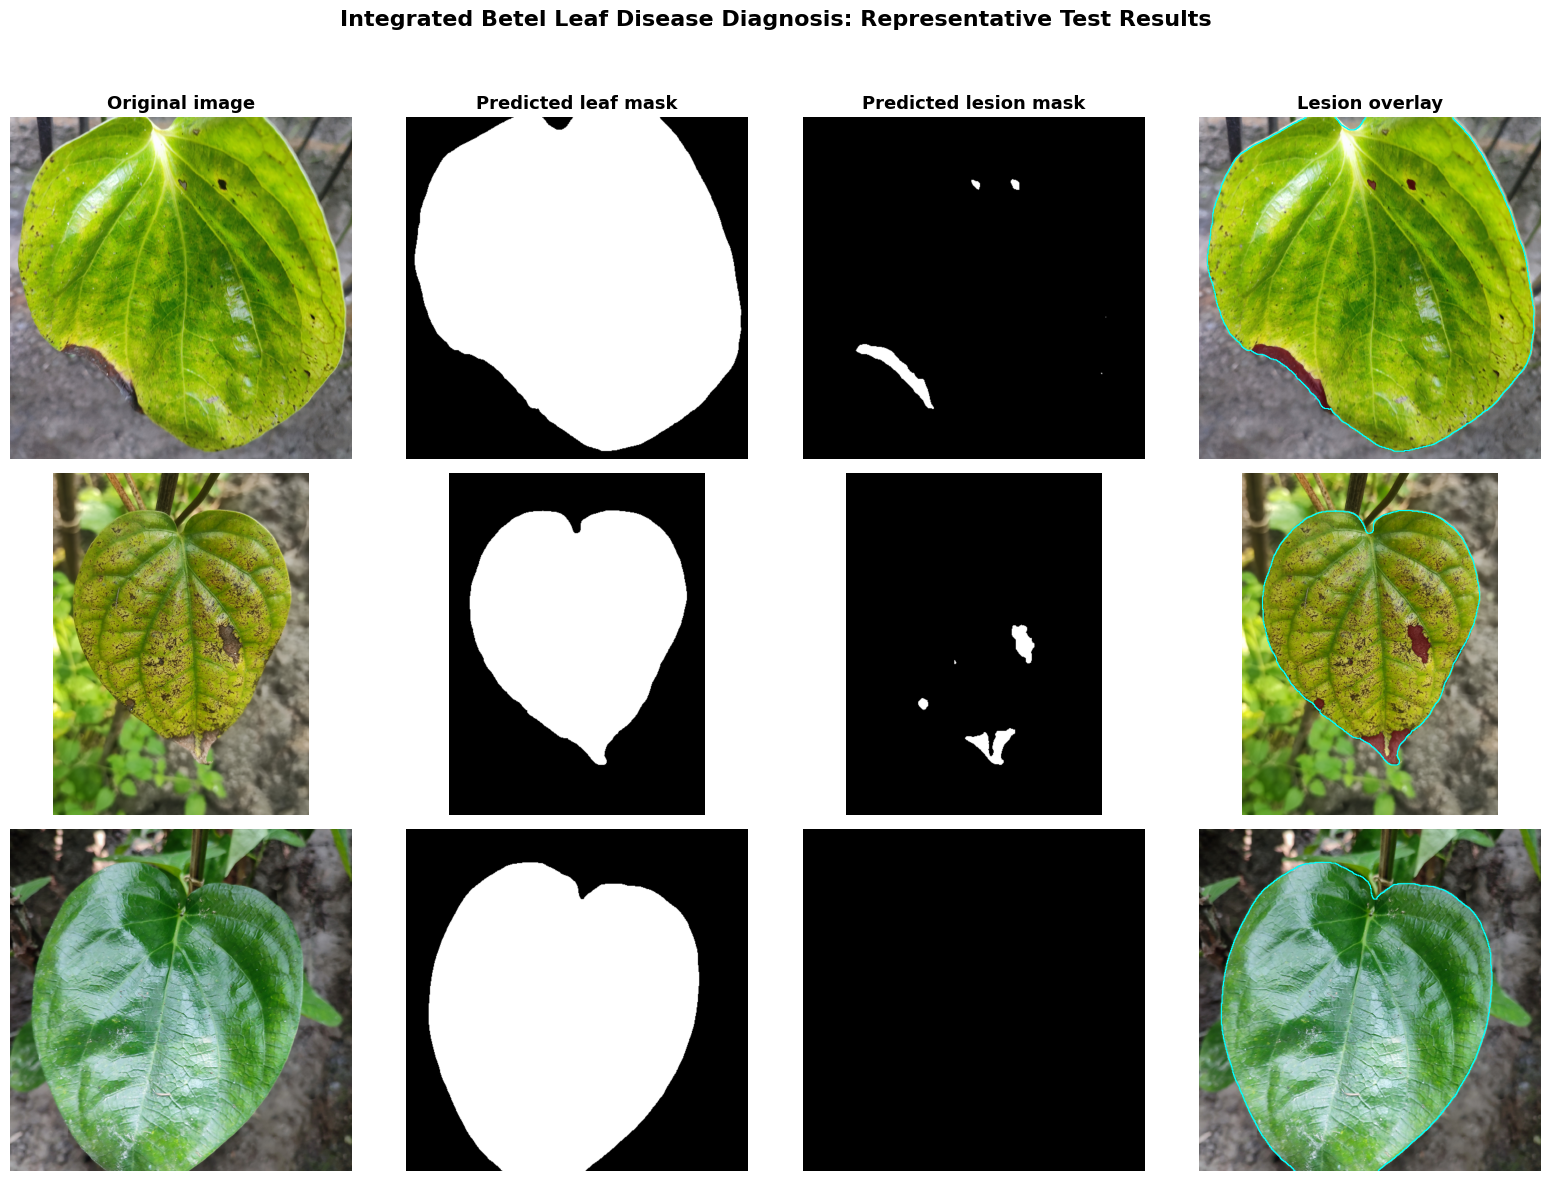


Figure files saved:
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage7_Integrated_Diagnostic_Pipeline/Results/Figures/stage7_representative_integrated_results_v1.png
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage7_Integrated_Diagnostic_Pipeline/Results/Figures/stage7_representative_integrated_results_v1.pdf


In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

# Folder for final scientific figures
figures_dir = os.path.join(
    PROJECT_ROOT,
    "Stage7_Integrated_Diagnostic_Pipeline",
    "Results",
    "Figures"
)
os.makedirs(figures_dir, exist_ok=True)

# Match original image paths to integrated results
image_paths = test_samples[
    ["filename", "image_path_resolved"]
].drop_duplicates("filename")

visual_df = integrated_df.merge(
    image_paths,
    on="filename",
    how="left",
    validate="one_to_one"
)

assert visual_df["image_path_resolved"].notna().all()

# Select correctly classified, representative images
selected_records = []

for disease_class in ["bacterial", "fungal", "healthy"]:

    class_df = visual_df[
        (visual_df["class"] == disease_class) &
        (visual_df["correct"] == True)
    ].copy()

    assert len(class_df) > 0, (
        f"No correctly classified {disease_class} image found."
    )

    median_burden = class_df[
        "lesion_area_ratio_percent"
    ].median()

    class_df["distance_from_median"] = (
        class_df["lesion_area_ratio_percent"] - median_burden
    ).abs()

    selected = class_df.sort_values(
        "distance_from_median"
    ).iloc[0]

    selected_records.append(selected)

selected_df = pd.DataFrame(selected_records)

print("SELECTED REPRESENTATIVE TEST IMAGES")

for _, row in selected_df.iterrows():
    print(
        f"{row['class']}: {row['filename']} | "
        f"Lesion burden: "
        f"{row['lesion_area_ratio_percent']:.3f}%"
    )

# Create the four-column scientific figure
fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(16, 12)
)

column_titles = [
    "Original image",
    "Predicted leaf mask",
    "Predicted lesion mask",
    "Lesion overlay"
]

for col, title in enumerate(column_titles):
    axes[0, col].set_title(
        title,
        fontsize=13,
        fontweight="bold"
    )

for row_index, (_, record) in enumerate(selected_df.iterrows()):

    # Load original image with orientation correction
    with Image.open(record["image_path_resolved"]) as img:
        original = ImageOps.exif_transpose(img).convert("RGB")

    original_array = np.asarray(original)

    # Load saved predicted masks
    leaf_mask = np.asarray(
        Image.open(record["leaf_mask_path"]).convert("L")
    ) > 0

    lesion_mask = np.asarray(
        Image.open(record["lesion_mask_path"]).convert("L")
    ) > 0

    # Confirm spatial alignment
    assert original_array.shape[:2] == leaf_mask.shape
    assert original_array.shape[:2] == lesion_mask.shape

    # Original image
    axes[row_index, 0].imshow(original_array)

    # Predicted leaf mask
    axes[row_index, 1].imshow(
        leaf_mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    # Predicted lesion mask
    axes[row_index, 2].imshow(
        lesion_mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    # Original image with lesion overlay and leaf boundary
    axes[row_index, 3].imshow(original_array)

    if lesion_mask.any():
        axes[row_index, 3].imshow(
            np.ma.masked_where(
                ~lesion_mask,
                lesion_mask
            ),
            cmap="Reds",
            alpha=0.55,
            vmin=0,
            vmax=1
        )

    if leaf_mask.any():
        axes[row_index, 3].contour(
            leaf_mask.astype(float),
            levels=[0.5],
            colors=["cyan"],
            linewidths=0.8
        )

    burden = record["lesion_area_ratio_percent"]

    axes[row_index, 0].set_ylabel(
        f"{record['class'].capitalize()}\n"
        f"Burden: {burden:.2f}%",
        fontsize=12,
        fontweight="bold"
    )

    for ax in axes[row_index]:
        ax.axis("off")

fig.suptitle(
    "Integrated Betel Leaf Disease Diagnosis: "
    "Representative Test Results",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

figure_path = os.path.join(
    figures_dir,
    "stage7_representative_integrated_results_v1.png"
)

pdf_path = os.path.join(
    figures_dir,
    "stage7_representative_integrated_results_v1.pdf"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

print("\nFigure files saved:")
print(figure_path)
print(pdf_path)

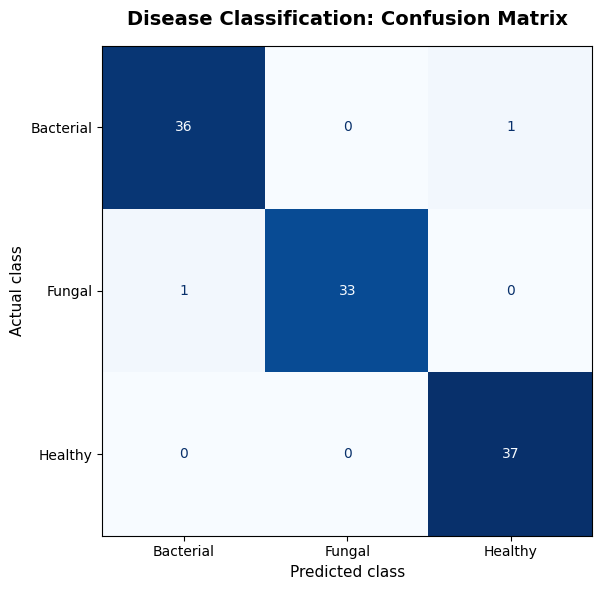

/tmp/ipykernel_873/1682975050.py:76: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


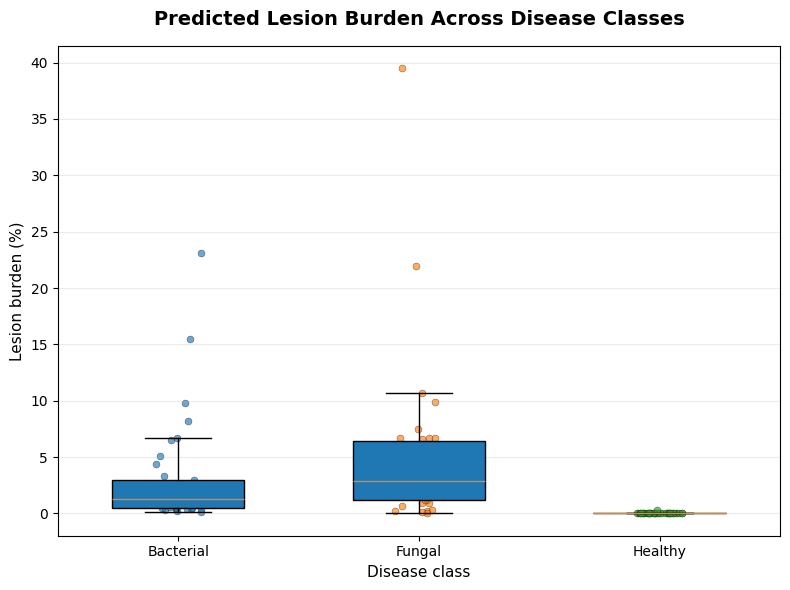

/tmp/ipykernel_873/1682975050.py:157: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_873/1682975050.py:157: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_873/1682975050.py:157: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_873/1682975050.py:157: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_873/1682975050.py:157: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been ren

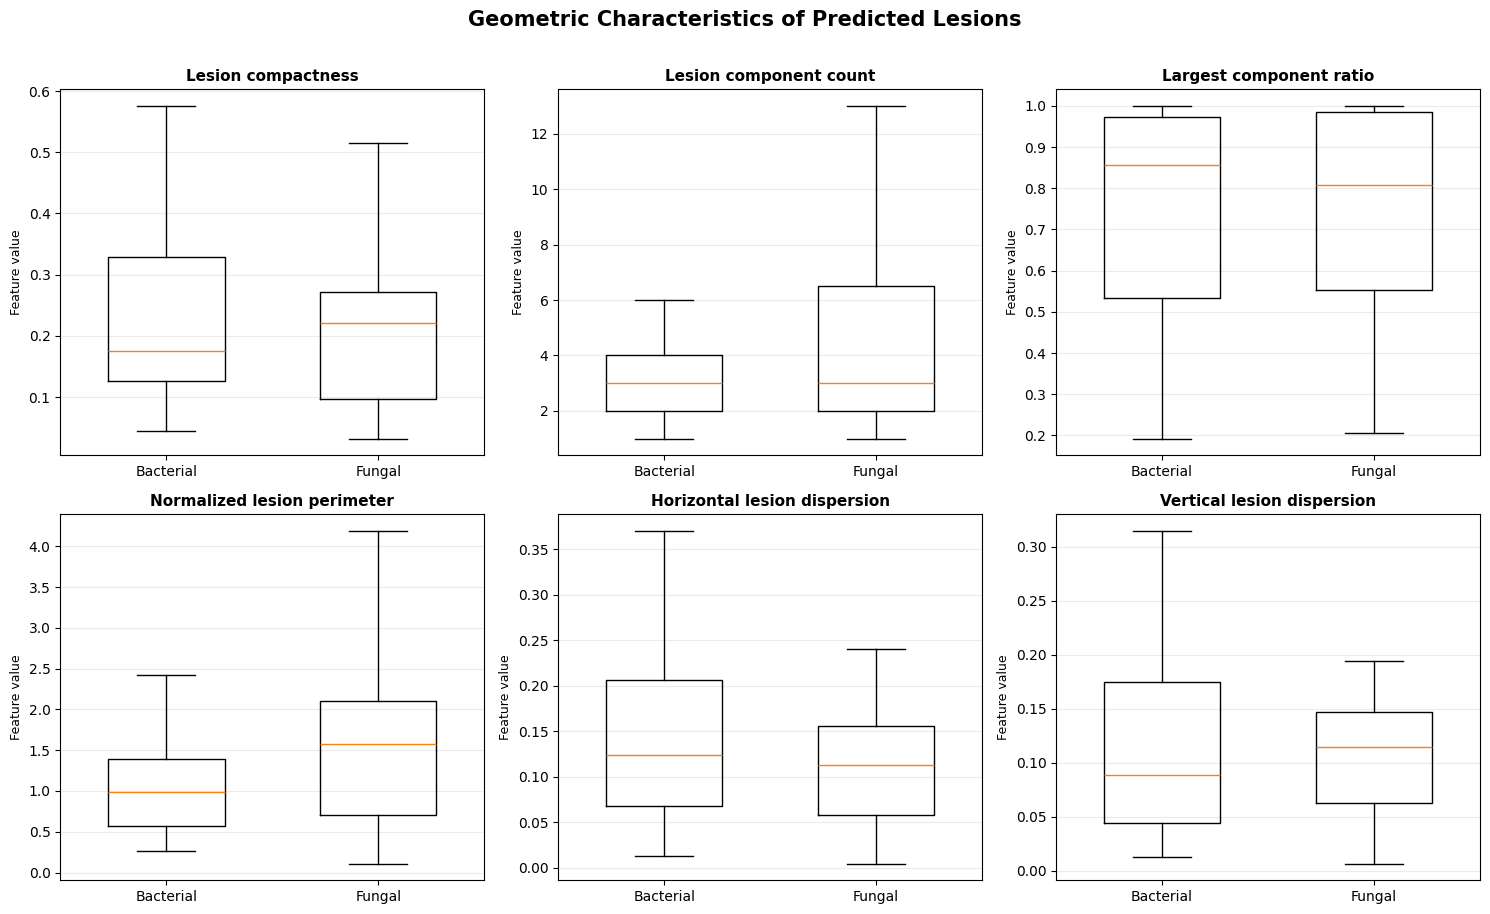

QUANTITATIVE FIGURES GENERATED

Saved files:
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage7_Integrated_Diagnostic_Pipeline/Results/Figures/stage7_confusion_matrix_v1.png
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage7_Integrated_Diagnostic_Pipeline/Results/Figures/stage7_confusion_matrix_v1.pdf
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage7_Integrated_Diagnostic_Pipeline/Results/Figures/stage7_lesion_burden_distribution_v1.png
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage7_Integrated_Diagnostic_Pipeline/Results/Figures/stage7_lesion_burden_distribution_v1.pdf
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage7_Integrated_Diagnostic_Pipeline/Results/Figures/stage7_geometric_feature_comparison_v1.png
/content/drive/MyDrive/Projectwork/Betel_Leaf_Final/Stage7_Integrated_Diagnostic_Pipeline/Results/Figures/stage7_geometric_feature_comparison_v1.pdf


In [35]:
import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Use the final Stage 7 integrated results
class_order = ["bacterial", "fungal", "healthy"]

figures_dir = os.path.join(
    PROJECT_ROOT,
    "Stage7_Integrated_Diagnostic_Pipeline",
    "Results",
    "Figures"
)
os.makedirs(figures_dir, exist_ok=True)

# Figure 1: Confusion matrix
y_true = integrated_df["actual_label"]
y_pred = integrated_df["predicted_label"]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_order
)

fig, ax = plt.subplots(figsize=(7, 6))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Bacterial", "Fungal", "Healthy"]
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

ax.set_title(
    "Disease Classification: Confusion Matrix",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Predicted class", fontsize=11)
ax.set_ylabel("Actual class", fontsize=11)

plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "stage7_confusion_matrix_v1.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    os.path.join(figures_dir, "stage7_confusion_matrix_v1.pdf"),
    bbox_inches="tight"
)
plt.show()


# Figure 2: Lesion burden distribution
fig, ax = plt.subplots(figsize=(8, 6))

burden_data = [
    integrated_df.loc[
        integrated_df["class"] == cls,
        "lesion_area_ratio_percent"
    ].dropna().values
    for cls in class_order
]

box = ax.boxplot(
    burden_data,
    labels=["Bacterial", "Fungal", "Healthy"],
    patch_artist=True,
    showfliers=False,
    widths=0.55
)

# Overlay individual observations
rng = np.random.default_rng(42)

for position, values in enumerate(burden_data, start=1):
    jitter = rng.uniform(-0.10, 0.10, size=len(values))

    ax.scatter(
        position + jitter,
        values,
        alpha=0.65,
        s=25,
        edgecolors="black",
        linewidths=0.3
    )

ax.set_title(
    "Predicted Lesion Burden Across Disease Classes",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Disease class", fontsize=11)
ax.set_ylabel("Lesion burden (%)", fontsize=11)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "stage7_lesion_burden_distribution_v1.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    os.path.join(figures_dir, "stage7_lesion_burden_distribution_v1.pdf"),
    bbox_inches="tight"
)
plt.show()


# Figure 3: Geometric characteristics of diseased leaves
diseased_df = integrated_df[
    integrated_df["class"].isin(["bacterial", "fungal"])
].copy()

geometry_features = [
    ("lesion_compactness", "Lesion compactness"),
    ("lesion_component_count", "Lesion component count"),
    ("largest_component_ratio", "Largest component ratio"),
    ("normalized_lesion_perimeter", "Normalized lesion perimeter"),
    ("lesion_dispersion_x", "Horizontal lesion dispersion"),
    ("lesion_dispersion_y", "Vertical lesion dispersion")
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 9)
)

for ax, (feature, title) in zip(
    axes.flat,
    geometry_features
):
    bacterial_values = diseased_df.loc[
        diseased_df["class"] == "bacterial",
        feature
    ].dropna().values

    fungal_values = diseased_df.loc[
        diseased_df["class"] == "fungal",
        feature
    ].dropna().values

    ax.boxplot(
        [bacterial_values, fungal_values],
        labels=["Bacterial", "Fungal"],
        showfliers=False,
        widths=0.55
    )

    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel("Feature value", fontsize=9)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Geometric Characteristics of Predicted Lesions",
    fontsize=15,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "stage7_geometric_feature_comparison_v1.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    os.path.join(figures_dir, "stage7_geometric_feature_comparison_v1.pdf"),
    bbox_inches="tight"
)
plt.show()


print("QUANTITATIVE FIGURES GENERATED")
print("\nSaved files:")

for filename in [
    "stage7_confusion_matrix_v1.png",
    "stage7_confusion_matrix_v1.pdf",
    "stage7_lesion_burden_distribution_v1.png",
    "stage7_lesion_burden_distribution_v1.pdf",
    "stage7_geometric_feature_comparison_v1.png",
    "stage7_geometric_feature_comparison_v1.pdf"
]:
    print(os.path.join(figures_dir, filename))

/tmp/ipykernel_873/2276682632.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


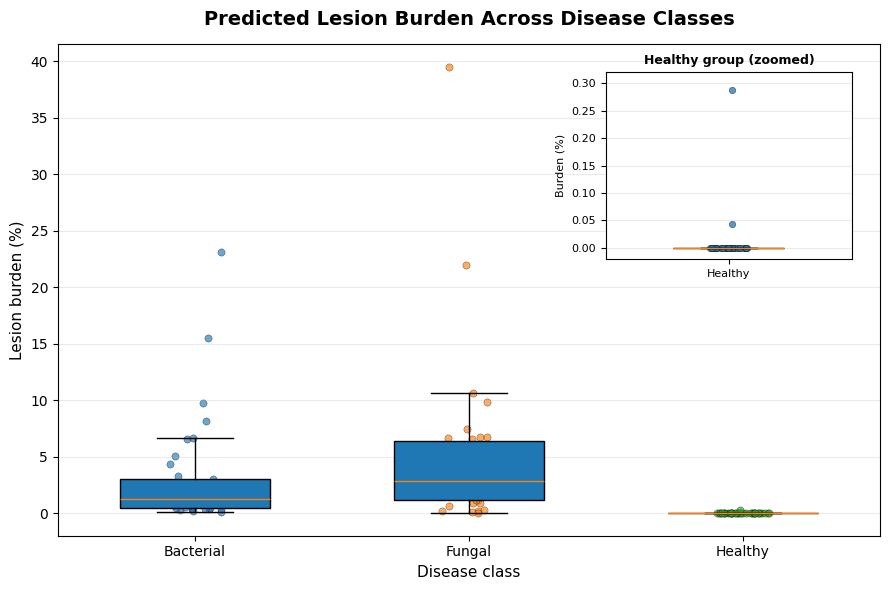

Updated lesion-burden figures saved.


In [36]:
import os
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

class_order = ["bacterial", "fungal", "healthy"]

burden_data = [
    integrated_df.loc[
        integrated_df["class"] == cls,
        "lesion_area_ratio_percent"
    ].dropna().values
    for cls in class_order
]

fig, ax = plt.subplots(figsize=(9, 6))

ax.boxplot(
    burden_data,
    tick_labels=["Bacterial", "Fungal", "Healthy"],
    patch_artist=True,
    showfliers=False,
    widths=0.55
)

rng = np.random.default_rng(42)

for position, values in enumerate(burden_data, start=1):
    jitter = rng.uniform(-0.10, 0.10, size=len(values))
    ax.scatter(
        position + jitter,
        values,
        alpha=0.65,
        s=27,
        edgecolors="black",
        linewidths=0.3
    )

ax.set_title(
    "Predicted Lesion Burden Across Disease Classes",
    fontsize=14,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("Disease class", fontsize=11)
ax.set_ylabel("Lesion burden (%)", fontsize=11)
ax.grid(axis="y", alpha=0.25)

# Zoomed view of healthy observations
inset = inset_axes(
    ax,
    width="30%",
    height="38%",
    loc="upper right",
    borderpad=2
)

healthy_values = burden_data[2]

inset.boxplot(
    [healthy_values],
    tick_labels=["Healthy"],
    patch_artist=True,
    showfliers=False,
    widths=0.45
)

healthy_jitter = rng.uniform(
    -0.08, 0.08, size=len(healthy_values)
)

inset.scatter(
    1 + healthy_jitter,
    healthy_values,
    alpha=0.75,
    s=22,
    edgecolors="black",
    linewidths=0.3
)

inset.set_ylim(-0.02, 0.32)
inset.set_title(
    "Healthy group (zoomed)",
    fontsize=9,
    fontweight="bold"
)
inset.set_ylabel("Burden (%)", fontsize=8)
inset.tick_params(axis="both", labelsize=8)
inset.grid(axis="y", alpha=0.25)

plt.tight_layout()

figures_dir = os.path.join(
    PROJECT_ROOT,
    "Stage7_Integrated_Diagnostic_Pipeline",
    "Results",
    "Figures"
)

plt.savefig(
    os.path.join(
        figures_dir,
        "stage7_lesion_burden_distribution_v2.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        figures_dir,
        "stage7_lesion_burden_distribution_v2.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

print("Updated lesion-burden figures saved.")

In [37]:
import os
import json
import pandas as pd
from PIL import Image

project_root = PROJECT_ROOT

stage7_root = os.path.join(
    project_root,
    "Stage7_Integrated_Diagnostic_Pipeline"
)

results_dir = os.path.join(stage7_root, "Results")
figures_dir = os.path.join(results_dir, "Figures")

required_files = {
    "Integrated test results": os.path.join(
        results_dir,
        "stage7_integrated_test_results_v1.csv"
    ),
    "Evaluation metrics": os.path.join(
        results_dir,
        "stage7_test_evaluation_metrics_v1.json"
    ),
    "Lesion burden summary": os.path.join(
        results_dir,
        "stage7_lesion_burden_summary_v1.csv"
    ),
    "Geometric profile summary": os.path.join(
        results_dir,
        "stage7_geometric_profile_summary_v1.csv"
    ),
    "Representative results PNG": os.path.join(
        figures_dir,
        "stage7_representative_integrated_results_v1.png"
    ),
    "Representative results PDF": os.path.join(
        figures_dir,
        "stage7_representative_integrated_results_v1.pdf"
    ),
    "Confusion matrix PNG": os.path.join(
        figures_dir,
        "stage7_confusion_matrix_v1.png"
    ),
    "Confusion matrix PDF": os.path.join(
        figures_dir,
        "stage7_confusion_matrix_v1.pdf"
    ),
    "Lesion burden PNG": os.path.join(
        figures_dir,
        "stage7_lesion_burden_distribution_v2.png"
    ),
    "Lesion burden PDF": os.path.join(
        figures_dir,
        "stage7_lesion_burden_distribution_v2.pdf"
    ),
    "Geometric comparison PNG": os.path.join(
        figures_dir,
        "stage7_geometric_feature_comparison_v1.png"
    ),
    "Geometric comparison PDF": os.path.join(
        figures_dir,
        "stage7_geometric_feature_comparison_v1.pdf"
    )
}

print("STAGE 7 — FINAL FILE AUDIT")

missing_files = []

for name, path in required_files.items():
    exists = os.path.isfile(path)
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")

    if not exists:
        missing_files.append(name)

assert not missing_files, (
    "Missing files: " + ", ".join(missing_files)
)

# Verify integrated test results
final_df = pd.read_csv(
    required_files["Integrated test results"]
)

assert len(final_df) == 108
assert final_df["filename"].is_unique
assert final_df["predicted_label"].notna().all()

assert final_df["leaf_mask_path"].notna().all()
assert final_df["lesion_mask_path"].notna().all()

# Verify all saved mask files
missing_masks = []

for _, row in final_df.iterrows():
    for mask_path in [
        row["leaf_mask_path"],
        row["lesion_mask_path"]
    ]:
        if not os.path.isfile(mask_path):
            missing_masks.append(mask_path)

print("\nMASK FILE VERIFICATION")
print("Missing mask files:", len(missing_masks))

assert len(missing_masks) == 0

# Verify saved classification metrics
with open(
    required_files["Evaluation metrics"],
    "r"
) as f:
    metrics = json.load(f)

print("\nCLASSIFICATION METRICS")
print("Accuracy:", metrics["accuracy"])
print("Macro F1:", metrics["macro_f1"])
print("Test images:", metrics["test_images"])

assert metrics["test_images"] == 108
assert abs(metrics["accuracy"] - 0.9815) < 0.001
assert abs(metrics["macro_f1"] - 0.9816) < 0.001

# Verify image dimensions and figure files
print("\nFIGURE INFORMATION")

for name, path in required_files.items():
    if name.endswith("PNG"):
        with Image.open(path) as image:
            print(
                f"{name}: {image.size}, "
                f"DPI metadata: {image.info.get('dpi')}"
            )

print("\nFINAL AUDIT PASSED")

STAGE 7 — FINAL FILE AUDIT
Integrated test results: FOUND
Evaluation metrics: FOUND
Lesion burden summary: FOUND
Geometric profile summary: FOUND
Representative results PNG: FOUND
Representative results PDF: FOUND
Confusion matrix PNG: FOUND
Confusion matrix PDF: FOUND
Lesion burden PNG: FOUND
Lesion burden PDF: FOUND
Geometric comparison PNG: FOUND
Geometric comparison PDF: FOUND

MASK FILE VERIFICATION
Missing mask files: 0

CLASSIFICATION METRICS
Accuracy: 0.9814814814814815
Macro F1: 0.9815714221684372
Test images: 108

FIGURE INFORMATION
Representative results PNG: (4652, 3543), DPI metadata: (299.9994, 299.9994)
Confusion matrix PNG: (1805, 1770), DPI metadata: (299.9994, 299.9994)
Lesion burden PNG: (2670, 1770), DPI metadata: (299.9994, 299.9994)
Geometric comparison PNG: (4467, 2742), DPI metadata: (299.9994, 299.9994)

FINAL AUDIT PASSED
